# Environment setup

In [37]:
from google.colab import drive
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/LOG6307E_project'
RAW_DIR = os.path.join(PROJECT_DIR, 'data', 'raw')
CLEAN_DIR = os.path.join(PROJECT_DIR, 'data', 'clean')
os.makedirs(CLEAN_DIR, exist_ok=True)

agent_pr = pd.read_parquet(os.path.join(RAW_DIR, 'agent_pr.parquet'))
human_pr = pd.read_parquet(os.path.join(RAW_DIR, 'human_pr.parquet'))
pr_commit_details = pd.read_parquet(os.path.join(RAW_DIR, 'pr_commit_details.parquet'))
overlap_urls = pd.read_csv(os.path.join(RAW_DIR, 'overlap_urls.csv'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
## data loads check
print("Agent PRs:", agent_pr.shape)
print("Human PRs:", human_pr.shape)
print("Commit details:", pr_commit_details.shape)
print("Overlap URLs:", len(overlap_urls))

Agent PRs: (33596, 17)
Human PRs: (6618, 14)
Commit details: (711923, 7)
Overlap URLs: 56


# Part 1 and 2 — Data Cleaning & Filtering

We start with the raw tables exported in Part 1 (`data/raw/`) and clean them to build our datasets for RQ1 and RQ2 (`data/clean/`).

Every filtering step and data decision is tracked in the table below along with the number of excluded records.

In [39]:
print("Agent PRs by agent:")
print(agent_pr['agent'].value_counts(dropna=False))

print("\nHuman PRs 'agent' column:")
print(human_pr['agent'].value_counts(dropna=False))

Agent PRs by agent:
agent
OpenAI_Codex    21799
Copilot          4970
Devin            4827
Cursor           1541
Claude_Code       459
Name: count, dtype: int64

Human PRs 'agent' column:
agent
Human    6618
Name: count, dtype: int64


## 2.0 Definitions & Scope

* **AI-Authored PRs:** Pull Requests from the AIDev agent dataset (`pull_request.parquet`) containing an identified agent in the `agent` column. We accept AIDev's attribution as-is, even if some of these PRs were technically opened through a developer's personal account.
* **Human-Authored PRs:** Pull Requests from the human dataset (`human_pull_request.parquet`), after filtering out bots, automated tools, and any overlapping entries with the agent dataset.


## Cleaning Decisions

| # | Decision | Rationale | Status | Rows affected |
|---|---|---|---|---|
| D1 | Remove overlapping PRs between AI and human datasets | Avoid ambiguous authorship and conflicting merge statuses | Done | 56 AI + 56 Human |
| D2 | Remove duplicate PRs by `id` and `html_url` | Avoid counting the same PR twice | Done | 0 |
| D3 | Exclude open PRs | Their final merge outcome is unknown | Done | 2,307 AI + 416 Human |
| D4 | Remove bots and automated accounts from human PRs | Keep the human agents as accurate as possible | Done | 1,081 Human |
| D5 | Remove PRs with inconsistent dates | Ensure valid creation, closing, and merge dates | Done | 0 |
| D6 | Exclude AI PRs with missing size information from RQ2 | PR size is required for RQ2 but not RQ1 | Done | 440 AI |
| D7 | Remove duplicate commit records | Avoid counting the same changes multiple times | Done | 44 records |
| D8 | Keep zero-line PRs and size outliers | Zero-line PRs may be valid, and large changes are part of the distribution | Done | 26 zero-line PRs kept |
| D9 | Task type classification | Not required for our research questions | Out of scope | N/A |


## 2.1 Cleaning the PR Datasets (RQ1)

### 2.1.1 Handling Dates, Missing Values, and Baseline Counts

In [40]:
# Convert date columns to datetime (UTC)
date_cols = ['created_at', 'closed_at', 'merged_at']
for df in (agent_pr, human_pr):
    for col in date_cols:
        df[col] = pd.to_datetime(df[col], utc=True)

# Null counts in key columns
key_cols = ['id', 'html_url', 'state', 'created_at', 'closed_at', 'merged_at']
print("Nulls in agent PRs:")
print(agent_pr[key_cols].isna().sum(), "\n")
print("Nulls in human PRs:")
print(human_pr[key_cols].isna().sum(), "\n")

# PR states
print("Agent PR states:")
print(agent_pr['state'].value_counts(dropna=False), "\n")
print("Human PR states:")
print(human_pr['state'].value_counts(dropna=False), "\n")

# Starting sizes (before any removal)
print("Starting size — agent PRs:", len(agent_pr))
print("Starting size — human PRs:", len(human_pr))

Nulls in agent PRs:
id               0
html_url         0
state            0
created_at       0
closed_at     2312
merged_at     9582
dtype: int64 

Nulls in human PRs:
id               0
html_url         0
state            0
created_at       0
closed_at      469
merged_at     1537
dtype: int64 

Agent PR states:
state
closed    31284
open       2312
Name: count, dtype: int64 

Human PR states:
state
closed    6149
open       469
Name: count, dtype: int64 

Starting size — agent PRs: 33596
Starting size — human PRs: 6618


### 2.1.2: D2, duplicates

In [41]:
# D2: remove duplicate PRs by id and by html_url
def remove_duplicates(df, name):
    before = len(df)
    dup_id = df.duplicated(subset='id').sum()
    dup_url = df.duplicated(subset='html_url').sum()
    print(f"{name}: duplicated ids = {dup_id}, duplicated html_urls = {dup_url}")

    df = df.drop_duplicates(subset='id', keep='first')
    df = df.drop_duplicates(subset='html_url', keep='first')

    print(f"{name}: {before} -> {len(df)} rows (removed {before - len(df)})\n")
    return df

agent_pr = remove_duplicates(agent_pr, "Agent PRs")
human_pr = remove_duplicates(human_pr, "Human PRs")

Agent PRs: duplicated ids = 0, duplicated html_urls = 0
Agent PRs: 33596 -> 33596 rows (removed 0)

Human PRs: duplicated ids = 0, duplicated html_urls = 0
Human PRs: 6618 -> 6618 rows (removed 0)



2.1.3: D1, overlaps

In [42]:
# D1: remove PRs whose html_url appears in both agent and human tables
overlap_set = set(overlap_urls['html_url'])
print("Overlapping URLs to remove:", len(overlap_set))

before_agent, before_human = len(agent_pr), len(human_pr)

agent_pr = agent_pr[~agent_pr['html_url'].isin(overlap_set)]
human_pr = human_pr[~human_pr['html_url'].isin(overlap_set)]

print(f"Agent PRs: {before_agent} -> {len(agent_pr)} rows (removed {before_agent - len(agent_pr)})")
print(f"Human PRs: {before_human} -> {len(human_pr)} rows (removed {before_human - len(human_pr)})")

# Check that no overlaps left
remaining = set(agent_pr['html_url']) & set(human_pr['html_url'])
print("Remaining overlaps:", len(remaining))

Overlapping URLs to remove: 56
Agent PRs: 33596 -> 33540 rows (removed 56)
Human PRs: 6618 -> 6562 rows (removed 56)
Remaining overlaps: 0


2.1.4: D4, inspect authors (nothing removed)

In [43]:
# D4: inspect human PR authors before deciding which are bots

# Accounts matching bot-like patterns
bot_pattern = r'\[bot\]|bot$|copilot|devin|codex|cursor|claude|dependabot|renovate|github-actions'
pattern_matches = human_pr[human_pr['user'].str.contains(bot_pattern, case=False, na=False)]
print("Human PRs from bot-like accounts:")
print(pattern_matches['user'].value_counts(), "\n")

# Most frequent human authors
print("Top 30 human PR authors:")
print(human_pr['user'].value_counts().head(30), "\n")

# Common accounts used by each agent
print("Top accounts per agent in the agent table:")
for agent_name in agent_pr['agent'].unique():
    top = agent_pr.loc[agent_pr['agent'] == agent_name, 'user'].value_counts().head(3)
    print(f"{agent_name}: {dict(top)}")

Human PRs from bot-like accounts:
user
dependabot[bot]                    421
renovate[bot]                      168
github-actions[bot]                143
dotnet-maestro[bot]                 50
calcom-bot                          27
gru-agent[bot]                      21
xerial-bot                          12
dotnet-bot                           8
liam-changeset-ci-trigger[bot]       7
dotnet-policy-service[bot]           6
codeflash-ai[bot]                    5
scala-steward-wvlet[bot]             5
rnuinoci[bot]                        4
resyntax-ci[bot]                     4
docs-bot                             3
vercel-release-bot                   3
youssef-backport-bot                 3
CBL-Mariner-Bot                      3
tembo-io[bot]                        2
pre-commit-ci[bot]                   2
octo-sts[bot]                        2
primer[bot]                          2
liam-license-ci-trigger[bot]         1
hash-worker[bot]                     1
jenkins-dependency-update

Cell 2.1.5: D4, check the ambiguous accounts (nothing removed)

In [44]:
# D4 (part 2): look at PR titles from ambiguous accounts before deciding
ambiguous = ['calcom-bot', 'xerial-bot', 'dotnet-bot', 'docs-bot', 'vercel-release-bot',
             'youssef-backport-bot', 'CBL-Mariner-Bot', 'ckanbot', 'SyliusBot', 'modularbot',
             'RepoBirdBot', 'kiwicom-orbit-bot', 'azure-sdk', 'airbyteio']

for account in ambiguous:
    titles = human_pr.loc[human_pr['user'] == account, 'title'].head(3).tolist()
    print(f"{account} ({(human_pr['user'] == account).sum()} PRs):")
    for t in titles:
        print("   -", t[:100])
    print()

calcom-bot (27 PRs):
   - feat: update translations via @lingodotdev
   - feat: update translations via @lingodotdev
   - feat: update translations via @lingodotdev

xerial-bot (12 PRs):
   - Update airframe-http, airframe-http-netty, ... to 2025.1.9
   - Update scalafmt-core to 3.9.1
   - Update sbt, sbt-dependency-tree, ... to 1.11.2

dotnet-bot (8 PRs):
   - Localized file check-in by OneLocBuild Task: Build definition ID 1309: Build ID 2661855
   - Localized file check-in by OneLocBuild Task: Build definition ID 1309: Build ID 2631589
   - Localized file check-in by OneLocBuild Task: Build definition ID 1309: Build ID 2668500

docs-bot (3 PRs):
   - Repo sync
   - Repo sync
   - Repo sync

vercel-release-bot (3 PRs):
   - Update font data
   - Update Turbopack development test manifest
   - Upgrade React from `14094f80-20250529` to `37054867-20250604`

youssef-backport-bot (3 PRs):
   - [rel/3.8] Ship props/targets of MSTest.TestFramework and MSTest.TestAdapter in both build and bu

Cell 2.1.6: D4, remove bots

In [45]:
# D4 (part 3): remove bot/automated accounts from the human table

# GitHub app accounts
is_suffix_bot = human_pr['user'].str.endswith('[bot]', na=False)

# Accounts identified manually from PR titles
manual_bots = ['calcom-bot', 'xerial-bot', 'dotnet-bot', 'docs-bot', 'vercel-release-bot',
               'youssef-backport-bot', 'CBL-Mariner-Bot', 'ckanbot', 'SyliusBot', 'modularbot',
               'RepoBirdBot', 'kiwicom-orbit-bot', 'azure-sdk', 'airbyteio']
is_manual_bot = human_pr['user'].isin(manual_bots)

# Check airbyteio titles
airbyte_titles = human_pr.loc[human_pr['user'] == 'airbyteio', 'title']
print("airbyteio PRs with 'up-to-date pipeline' in title:",
      airbyte_titles.str.contains('up-to-date pipeline', na=False).sum(), "/", len(airbyte_titles), "\n")

print("Removed by [bot] suffix:", is_suffix_bot.sum())
print("Removed by manual list:", is_manual_bot.sum())

before_human = len(human_pr)
human_pr = human_pr[~(is_suffix_bot | is_manual_bot)]

print(f"Human PRs: {before_human} -> {len(human_pr)} rows "
      f"(removed {before_human - len(human_pr)})")

airbyteio PRs with 'up-to-date pipeline' in title: 136 / 136 

Removed by [bot] suffix: 852
Removed by manual list: 229
Human PRs: 6562 -> 5481 rows (removed 1081)


Cell 2.1.7: D3, open PRs

In [46]:
# D3: exclude open PRs
before_agent, before_human = len(agent_pr), len(human_pr)

agent_pr = agent_pr[agent_pr['state'] == 'closed']
human_pr = human_pr[human_pr['state'] == 'closed']

print(f"Agent PRs: {before_agent} -> {len(agent_pr)} rows (removed {before_agent - len(agent_pr)})")
print(f"Human PRs: {before_human} -> {len(human_pr)} rows (removed {before_human - len(human_pr)})")

# Verifying for missing closing date
print("Remaining PRs without closed_at agent:", agent_pr['closed_at'].isna().sum(),
      "| human:", human_pr['closed_at'].isna().sum())

Agent PRs: 33540 -> 31233 rows (removed 2307)
Human PRs: 5481 -> 5065 rows (removed 416)
Remaining PRs without closed_at agent: 0 | human: 0


Cell 2.1.8: D5, inconsistent dates

In [47]:
# D5: drop PRs with inconsistent dates
def date_issues(df):
    return {
        'closed before created': df['closed_at'] < df['created_at'],
        'merged before created': df['merged_at'] < df['created_at'],
        'merged after closed':   df['merged_at'] > df['closed_at'],
    }

for name, df in [("Agent PRs", agent_pr), ("Human PRs", human_pr)]:
    print(f"{name}:")
    for issue, mask in date_issues(df).items():
        print(f"   {issue}: {mask.sum()}")

def drop_inconsistent(df, name):
    before = len(df)
    bad = pd.concat(date_issues(df), axis=1).any(axis=1)
    df = df[~bad]
    print(f"{name}: {before} -> {len(df)} rows (removed {before - len(df)})")
    return df

print()
agent_pr = drop_inconsistent(agent_pr, "Agent PRs")
human_pr = drop_inconsistent(human_pr, "Human PRs")

Agent PRs:
   closed before created: 0
   merged before created: 0
   merged after closed: 0
Human PRs:
   closed before created: 0
   merged before created: 0
   merged after closed: 0

Agent PRs: 31233 -> 31233 rows (removed 0)
Human PRs: 5065 -> 5065 rows (removed 0)


Cell 2.1.9: combine and save

In [48]:
# Save cleaned tables
agent_pr = agent_pr.copy()
human_pr = human_pr.copy()

agent_pr.to_parquet(os.path.join(CLEAN_DIR, 'agent_pr_clean.parquet'), index=False)
human_pr.to_parquet(os.path.join(CLEAN_DIR, 'human_pr_clean.parquet'), index=False)

# Check saved files
for name, df in [('agent_pr_clean', agent_pr), ('human_pr_clean', human_pr)]:
    saved = pd.read_parquet(os.path.join(CLEAN_DIR, f'{name}.parquet'))
    print(f"{name}: in memory {df.shape} | on disk {saved.shape}")

agent_pr_clean: in memory (31233, 17) | on disk (31233, 17)
human_pr_clean: in memory (5065, 14) | on disk (5065, 14)


Cell 2.1.10: create merge rate table, agent and human combined

In [49]:
# Merge rate table (rate calculated over closed PRs, since open PRs were removed in D3)
def merge_summary(df, label):
    total = len(df)
    merged = int(df['merged_at'].notna().sum())
    return {
        'group': label,
        'total_prs': total,
        'merged_prs': merged,
        'merge_rate': round(merged / total, 4),
    }

merge_rate_table = pd.DataFrame([
    merge_summary(agent_pr, 'AI'),
    merge_summary(human_pr, 'Human'),
])

# Save merge_rate_table to the repo
os.makedirs(CLEAN_DIR, exist_ok=True)
merge_rate_table.to_csv(os.path.join(CLEAN_DIR, 'merge_rate_table.csv'), index=False)

# Show the table
merge_rate_table

,group,total_prs,merged_prs,merge_rate
0,AI,31233,23977,0.7677
1,Human,5065,4287,0.8464


## 2.2 Cleaning table pr_size(RQ2)

### 2.2.1 load pr_size table

In [50]:
pr_commit_details = pd.read_parquet(os.path.join(RAW_DIR, 'pr_commit_details.parquet'))

agent_pr_clean = agent_pr.copy()

print("Raw commit details:", pr_commit_details.shape)
print(pr_commit_details.dtypes, "\n")
print("Nulls:\n", pr_commit_details.isna().sum(), "\n")

Raw commit details: (711923, 7)
pr_id          int64
sha           object
filename      object
status        object
additions    float64
deletions    float64
changes      float64
dtype: object 

Nulls:
 pr_id           0
sha             0
filename     5132
status       5132
additions    5132
deletions    5132
changes      5132
dtype: int64 



2.2.2: keep just cleaned agent PRs

In [51]:
before = len(pr_commit_details)
details = pr_commit_details[pr_commit_details['pr_id'].isin(agent_pr['id'])].copy()
print(f"Rows: {before} -> {len(details)} (removed {before - len(details)})")
print("Cleaned agent PRs with file data:", details['pr_id'].nunique(), "of", agent_pr['id'].nunique())

Rows: 711923 -> 612256 (removed 99667)
Cleaned agent PRs with file data: 31217 of 31233


2.2.3: D7, remove duplicate rows

In [52]:
key = ['pr_id', 'sha', 'filename']
dup_mask = details.duplicated(subset=key, keep=False)
print("Rows involved in duplicate keys:", dup_mask.sum())

# look into this
# Are the duplicates identical, or do they carry different values?
conflicting = (details[dup_mask]
               .groupby(key)[['additions', 'deletions']]
               .nunique().gt(1).any(axis=1).sum())

before = len(details)
details = details.drop_duplicates(subset=key, keep='first')
print(f"Rows: {before} -> {len(details)} (removed {before - len(details)})")

Rows involved in duplicate keys: 88
Rows: 612256 -> 612212 (removed 44)


2.2.4: remove rows with missing values in additions and deletions

In [53]:
both_null = details[['additions', 'deletions']].isna().all(axis=1)
print("Rows with both additions and deletions missing:", both_null.sum())

before = len(details)
details = details[~both_null].copy()
print(f"Rows: {before} -> {len(details)} (removed {before - len(details)})")

Rows with both additions and deletions missing: 4047
Rows: 612212 -> 608165 (removed 4047)


2.2.5: create pr_size_clean table

In [54]:
pr_size_clean = (
    details.groupby('pr_id')
    .agg(
        additions=('additions', 'sum'),
        deletions=('deletions', 'sum'),
        files_changed=('filename', 'nunique'),
    )
    .reset_index()
)
pr_size_clean['change_size'] = pr_size_clean['additions'] + pr_size_clean['deletions']

print("pr_size_clean:", pr_size_clean.shape)

# Show the table
pr_size_clean

pr_size_clean: (30793, 5)


,pr_id,additions,deletions,files_changed,change_size
0,2756921963,848.0,344.0,15,1192.0
1,2757103560,517.0,262.0,16,779.0
2,2757124156,1.0,1.0,1,2.0
3,2757125491,1.0,1.0,1,2.0
4,2757179026,1633.0,169.0,15,1802.0
...,...,...,...,...,...
30788,3278090865,70.0,47.0,2,117.0
30789,3278111128,17.0,26.0,1,43.0
30790,3278116754,9.0,6.0,1,15.0
30791,3278129499,111.0,27.0,3,138.0


Cell 2.2.6: creat the join table, between pr_size_clean and agent_pr_clean

In [55]:
rq2 = agent_pr_clean.merge(pr_size_clean, left_on='id', right_on='pr_id',
                           how='left', validate='one_to_one')
rq2 = rq2.drop(columns='pr_id')

# Outcome variable for RQ2
rq2['is_merged'] = rq2['merged_at'].notna()

# D6: PRs with no usable size (RQ2 dataset only)
no_size = rq2['change_size'].isna()
print("D6 - PRs excluded for missing size:", no_size.sum())
print("   merge rate of excluded PRs:", round(rq2.loc[no_size, 'is_merged'].mean(), 4))
print("   merge rate of kept PRs:    ", round(rq2.loc[~no_size, 'is_merged'].mean(), 4))
rq2 = rq2[~no_size].copy()

# D8: keep zero-line PRs, but report them
print("D8 - zero-line PRs kept:", (rq2['change_size'] == 0).sum())

# Log-scaled size (change_size is heavily right-skewed)
rq2['log_size'] = np.log1p(rq2['change_size'])

print(rq2['change_size'].describe())
print("Final RQ2 dataset:", rq2.shape)

rq2.to_parquet(os.path.join(CLEAN_DIR, 'agent_pr_size_clean.parquet'), index=False)
saved = pd.read_parquet(os.path.join(CLEAN_DIR, 'agent_pr_size_clean.parquet'))
print("On disk:", saved.shape)

D6 - PRs excluded for missing size: 440
   merge rate of excluded PRs: 0.0159
   merge rate of kept PRs:     0.7784
D8 - zero-line PRs kept: 26
count    3.079300e+04
mean     1.716440e+03
std      1.614083e+04
min      0.000000e+00
25%      2.600000e+01
50%      9.300000e+01
75%      3.300000e+02
max      1.451946e+06
Name: change_size, dtype: float64
Final RQ2 dataset: (30793, 23)
On disk: (30793, 23)


# Part 3 : Metrics definition

### Data and Variable Dictionary

This reference section outlines the schema and variables used throughout our analyses for **RQ1** and **RQ2**. It details both the core fields retrieved from the GitHub API and the custom metrics calculated during the data cleaning process.

#### 1. Pull Requests Table (`agent_pr_clean` & `human_pr_clean`)

This table contains metadata for closed PRs after applying our exclusion criteria (removing duplicates, shared accounts, and automated bots)

| Variable Name | Type | Description | Source / Derivation |
| :--- | :--- | :--- | :--- |
| `id` | `int64` | Unique GitHub identifier for the pull request. | GitHub API (`id`) |
| `number` | `int64` | The pull request number within its specific repository. | GitHub API (`number`) |
| `title` | `object` | The title text of the pull request. | GitHub API (`title`) |
| `body` | `object` | The body description text written in Markdown. | GitHub API (`body`) |
| `agent` | `object` | The creator group label (e.g., specific developer tool names like `OpenAI_Codex`, `Copilot`, `Devin`, `Cursor`, `Claude_Code` or `Human` for the control group). | *(Assigned during table compilation)* |
| `user_id` | `int64` | Unique numeric identifier for the author's account. | GitHub API (`user.id`) |
| `user` | `object` | The GitHub username of the author. | GitHub API (`user.login`) |
| `state` | `object` | The current state of the PR (restricted to `closed` in this dataset). | GitHub API (`state`) |
| `created_at` | `datetime64[ns, UTC]` | Timestamp showing when the PR was opened. | GitHub API (`created_at`) |
| `closed_at` | `datetime64[ns, UTC]` | Timestamp showing when the PR was closed. | GitHub API (`closed_at`) |
| `merged_at` | `datetime64[ns, UTC]` | Timestamp showing when the PR was merged (records `NaT` if the PR was closed without merging). | GitHub API (`pull_request.merged_at`) |
| `repo_id` | `int64` | Unique identifier of the repository hosting the PR. | GitHub API |
| `repo_url` | `object` | API endpoint for the associated repository. | GitHub API |
| `html_url` | `object` | Web link to the pull request page. | GitHub API (`html_url`) |
| `merged` | `bool` | Initial boolean field indicating if the PR was merged. | GitHub API |
| `number_of_comments` | `float64` | Total comment count on the pull request thread. | GitHub API |
| `number_of_reviews` | `float64` | Total number of formal reviews submitted for this pull request. | GitHub API |

---

#### 2. Commit Details Table (`pr_commit_details` - Raw Data)

This raw table is used to compute change metrics by looking at individual files modified in each PR

| Variable Name | Type | Description | Source / Derivation |
| :--- | :--- | :--- | :--- |
| `pr_id` | `int64` | The ID of the pull request associated with the commit. | GitHub API (`pr_id`) |
| `sha` | `object` | Unique commit hash (SHA-1). | GitHub API (`sha`) |
| `filename` | `object` | The relative path of the modified file in the repository. | GitHub API (`filename`) |
| `status` | `object` | The type of change made to the file (e.g., added, modified, deleted). | GitHub API (`status`) |
| `additions` | `float64` | Number of lines of code added to this file. | GitHub API (`additions`) |
| `deletions` | `float64` | Number of lines of code deleted from this file. | GitHub API (`deletions`) |
| `changes` | `float64` | The sum of additions and deletions for this file. | GitHub API (`changes`) |

---

#### 3. PR Size & Success Table (`agent_pr_size_clean` - RQ2 Dataset)

This final dataset combines the aggregate modification metrics with our clean PR records

| Variable Name | Type | Description | Source / Derivation |
| :--- | :--- | :--- | :--- |
| `additions` | `float64` | Sum of all code lines added in this pull request. | Sum of `additions` grouped by `pr_id` |
| `deletions` | `float64` | Sum of all code lines deleted in this pull request. | Sum of `deletions` grouped by `pr_id` |
| `files_changed` | `int64` | Count of unique files modified. | Count of unique `filename` grouped by `pr_id` |
| `change_size` | `float64` | Total volume of changes made (combined additions and deletions). | `additions` + `deletions` |
| `is_merged` | `bool` | Success indicator showing if the PR was merged successfully. | Derived from non-null values in `merged_at` |
| `is_merged_int` | `int64` | Numeric value (1 for merged, 0 for rejected) used to fit our statistical models. | `is_merged` converted to an integer |
| `log_size` | `float64` | Log-transformed change size, calculated to handle outliers and right-skewness while keeping empty changes. | Calculated as `log(change_size + 1)` |

# Part 4 : Analysis

###RQ1 Analysis: How do merge rates differ between AI-authored and human-authored pull requests?

In [66]:
# --- Counts from merge_rate_table ---
ai = merge_rate_table.loc[merge_rate_table['group'] == 'AI'].iloc[0]
hu = merge_rate_table.loc[merge_rate_table['group'] == 'Human'].iloc[0]

ai_m, ai_t = int(ai['merged_prs']), int(ai['total_prs'])
hu_m, hu_t = int(hu['merged_prs']), int(hu['total_prs'])
ai_n, hu_n = ai_t - ai_m, hu_t - hu_m          # non-merged

# --- 1) Difference in merge probability (percentage points) ---
p_ai, p_hu = ai_m / ai_t, hu_m / hu_t
diff = p_ai - p_hu
se_diff = np.sqrt(p_ai*(1-p_ai)/ai_t + p_hu*(1-p_hu)/hu_t)
diff_ci = (diff - 1.96*se_diff, diff + 1.96*se_diff)

# --- 2) Odds ratio (AI vs Human) ---
odds_ai = ai_m / ai_n
odds_hu = hu_m / hu_n
table = np.array([[ai_m, ai_n],
                  [hu_m, hu_n]])
OR = odds_ai / odds_hu
se_log_or = np.sqrt((1 / table).sum())
or_ci = np.exp(np.log(OR) + np.array([-1.96, 1.96]) * se_log_or)

# --- 3) Significance (chi-square test) ---
chi2, p_val, dof, _ = chi2_contingency(table, correction=False)

# --- Display ---
print("RQ1: AI vs Human merge outcomes\n")

print(f"Merge rate  AI: {p_ai:.1%}  |  Human: {p_hu:.1%}\n")

print("1) Difference in probability")
print(f"   {diff*100:+.1f} percentage points "
      f"(95% CI [{diff_ci[0]*100:+.1f}, {diff_ci[1]*100:+.1f}])")
print("   -> AI PRs are merged less often than human PRs, "
      "by this many percentage points (difference between the two merge rates).\n")

print("2) Odds ratio (AI vs Human)")
print(f"   Odds of merge (merged per unmerged PR):")
print(f"      AI    = {ai_m:,} / {ai_n:,} = {odds_ai:.2f}")
print(f"      Human = {hu_m:,} / {hu_n:,} = {odds_hu:.2f}")
print(f"   OR = {odds_ai:.2f} / {odds_hu:.2f} ≈ {OR:.2f} "
      f"(95% CI [{or_ci[0]:.2f}, {or_ci[1]:.2f}])")
print(f"   -> The odds of an AI PR being merged are about "
      f"{(1-OR)*100:.0f}% lower than for a human PR")
print("   -> (OR < 1: AI disadvantaged | OR = 1: no difference | OR > 1: AI advantaged)\n")

print("3) Statistical significance (chi-square test)")
print(f"   chi2 = {chi2:.2f}, p-value = {p_val:.3e}")
print("   -> This test checks whether author type (AI vs Human) is associated with merge outcome")

if p_val < 0.05:
    print("   -> p < 0.05: There is a statistically significant association between author type and merge outcome")
    print("   -> This does not mean that author type directly causes the difference in merge rates")
else:
    print("   -> p >= 0.05: We did not find enough evidence of an association between author type and merge outcome")

RQ1: AI vs Human merge outcomes

Merge rate  AI: 76.8%  |  Human: 84.6%

1) Difference in probability
   -7.9 percentage points (95% CI [-9.0, -6.8])
   -> AI PRs are merged less often than human PRs, by this many percentage points (difference between the two merge rates).

2) Odds ratio (AI vs Human)
   Odds of merge (merged per unmerged PR):
      AI    = 23,977 / 7,256 = 3.30
      Human = 4,287 / 778 = 5.51
   OR = 3.30 / 5.51 ≈ 0.60 (95% CI [0.55, 0.65])
   -> The odds of an AI PR being merged are about 40% lower than for a human PR
   -> (OR < 1: AI disadvantaged | OR = 1: no difference | OR > 1: AI advantaged)

3) Statistical significance (chi-square test)
   chi2 = 156.69, p-value = 5.997e-36
   -> This test checks whether author type (AI vs Human) is associated with merge outcome
   -> p < 0.05: There is a statistically significant association between author type and merge outcome
   -> This does not mean that author type directly causes the difference in merge rates


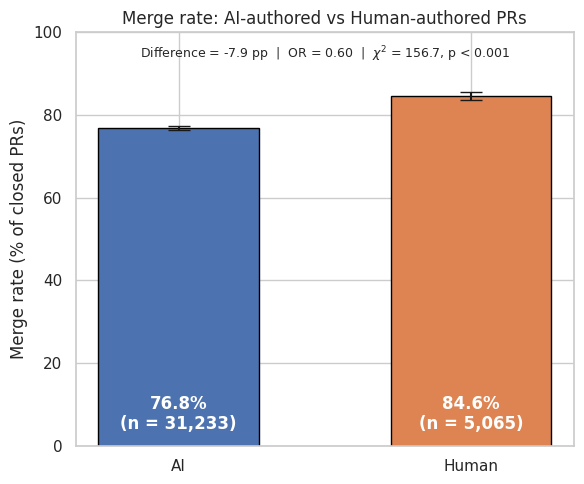

In [57]:
sns.set_theme(style="whitegrid")
FIG_DIR = os.path.join(PROJECT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Wilson 95% CI for each group
ai_lo, ai_hi = proportion_confint(ai_m, ai_t, alpha=0.05, method='wilson')
hu_lo, hu_hi = proportion_confint(hu_m, hu_t, alpha=0.05, method='wilson')

groups = ['AI', 'Human']
rates = np.array([p_ai, p_hu]) * 100
err_low = rates - np.array([ai_lo, hu_lo]) * 100
err_high = np.array([ai_hi, hu_hi]) * 100 - rates

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(groups, rates, yerr=[err_low, err_high], capsize=8,
              color=['#4C72B0', '#DD8452'], edgecolor='black', width=0.55)

for bar, rate, n in zip(bars, rates, [ai_t, hu_t]):
    ax.text(bar.get_x() + bar.get_width()/2, 3, f"{rate:.1f}%\n(n = {n:,})",
            ha='center', va='bottom', color='white', fontweight='bold')

ax.set_ylim(0, 100)
ax.set_ylabel("Merge rate (% of closed PRs)")
ax.set_title("Merge rate: AI-authored vs Human-authored PRs")
ax.text(0.5, 0.97,
        f"Difference = {diff*100:+.1f} pp  |  OR = {OR:.2f}  |  "
        f"$\\chi^2$ = {chi2:.1f}, p < 0.001",
        transform=ax.transAxes, ha='center', va='top', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'rq1_merge_rate_ai_vs_human.png'), dpi=300)
plt.show()

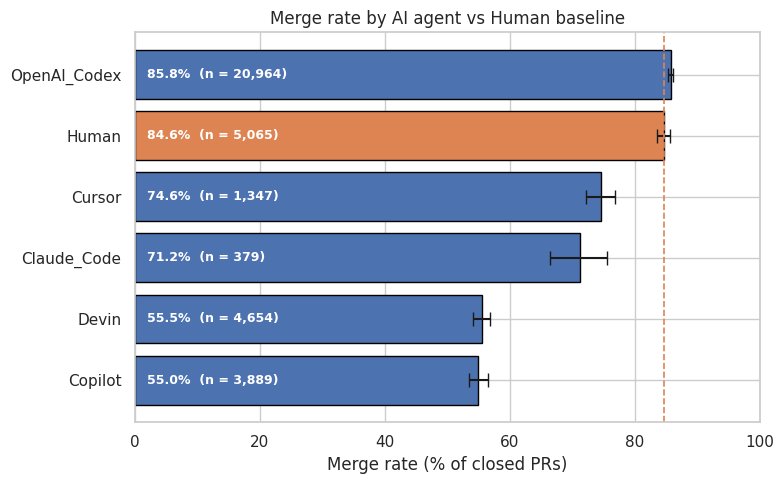

,agent,total,merged,rate
4,OpenAI_Codex,20964,17979,85.8
0,Human,5065,4287,84.6
2,Cursor,1347,1005,74.6
0,Claude_Code,379,270,71.2
3,Devin,4654,2584,55.5
1,Copilot,3889,2139,55.0


In [58]:
# Merge rate per agent (cleaned agent PRs)
agent_stats = (agent_pr.groupby('agent')
               .agg(total=('id', 'size'), merged=('merged_at', lambda s: s.notna().sum()))
               .reset_index())
agent_stats['rate'] = agent_stats['merged'] / agent_stats['total'] * 100
ci = agent_stats.apply(lambda r: proportion_confint(r['merged'], r['total'],
                                                    alpha=0.05, method='wilson'), axis=1)
agent_stats['lo'] = [c[0] * 100 for c in ci]
agent_stats['hi'] = [c[1] * 100 for c in ci]

# Add the Human group as reference, then sort by merge rate
human_row = pd.DataFrame([{'agent': 'Human', 'total': hu_t, 'merged': hu_m,
                           'rate': p_hu * 100, 'lo': hu_lo * 100, 'hi': hu_hi * 100}])
plot_df = pd.concat([agent_stats, human_row]).sort_values('rate', ascending=True)

colors = ['#DD8452' if a == 'Human' else '#4C72B0' for a in plot_df['agent']]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_df['agent'], plot_df['rate'],
        xerr=[plot_df['rate'] - plot_df['lo'], plot_df['hi'] - plot_df['rate']],
        color=colors, edgecolor='black', capsize=5)

for i, (rate, n) in enumerate(zip(plot_df['rate'], plot_df['total'])):
    ax.text(2, i, f"{rate:.1f}%  (n = {n:,})", va='center',
            color='white', fontweight='bold', fontsize=9)

ax.axvline(p_hu * 100, color='#DD8452', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 100)
ax.set_xlabel("Merge rate (% of closed PRs)")
ax.set_title("Merge rate by AI agent vs Human baseline")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'rq1_merge_rate_by_agent.png'), dpi=300)
plt.show()

display(plot_df[['agent', 'total', 'merged', 'rate']].round(1).sort_values('rate', ascending=False))

###RQ2 Analysis: How does the size of AI-authored pull requests relate to their likelihood of being merged?


In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

rq2_df = rq2.copy()

print("Dataset shape:", rq2_df.shape)
print("Available columns:", rq2_df.columns.tolist())

Dataset shape: (30793, 23)
Available columns: ['id', 'number', 'title', 'body', 'agent', 'user_id', 'user', 'state', 'created_at', 'closed_at', 'merged_at', 'repo_id', 'repo_url', 'html_url', 'merged', 'number_of_comments', 'number_of_reviews', 'additions', 'deletions', 'files_changed', 'change_size', 'is_merged', 'log_size']


#### 3.1 Descriptive Statistics and Visualization
We first compare the size metrics (`change_size`) between merged PRs (`is_merged == True`) and unmerged PRs.

In [61]:
# checking for Prs with a change_size = 0
zero_size_prs = rq2_df[rq2_df['change_size'] == 0]

print(f"Nb of PRs with change_size = 0 : {len(zero_size_prs)}")
print(f"merge rate of PRS with 0 change : {zero_size_prs['is_merged'].mean() * 100:.2f}%")

# sample
if len(zero_size_prs) > 0:
    display(zero_size_prs[['id', 'title', 'agent', 'is_merged', 'additions','deletions','change_size']].head())

Nb of PRs with change_size = 0 : 26
merge rate of PRS with 0 change : 76.92%


,id,title,agent,is_merged,additions,deletions,change_size
3727,3248123564,Fix email matching logic and add detailed logg...,Copilot,False,0.0,0.0,0.0
5455,3177522638,Rename GitHub tests README,OpenAI_Codex,True,0.0,0.0,0.0
11012,3208519267,Move archived packages,OpenAI_Codex,False,0.0,0.0,0.0
11354,3204506715,Refactor any2mochi golden helpers,OpenAI_Codex,False,0.0,0.0,0.0
11409,3164996458,Migrate modules to filename layout,OpenAI_Codex,True,0.0,0.0,0.0


In [62]:
# Validation of PR size dispersions:
print("=== Dispersion of PR size ===")
print(f"Min size : {rq2_df['change_size'].min()} lines")
print(f"Median size  : {rq2_df['change_size'].median()} lines")
print(f"Mean size : {rq2_df['change_size'].mean():.1f} lins")
print(f"Std dev      : {rq2_df['change_size'].std():.1f} lines")
print(f"Max size : {rq2_df['change_size'].max()} lines")

print("\n=== Percentiles ===")
for p in [90, 95, 99, 99.9]:
    print(f"{p}% of PRs have a size less or equal to : {rq2_df['change_size'].quantile(p/100):.1f} lines")

=== Dispersion of PR size ===
Min size : 0.0 lines
Median size  : 93.0 lines
Mean size : 1716.4 lins
Std dev      : 16140.8 lines
Max size : 1451946.0 lines

=== Percentiles ===
90% of PRs have a size less or equal to : 1647.0 lines
95% of PRs have a size less or equal to : 5027.2 lines
99% of PRs have a size less or equal to : 30719.9 lines
99.9% of PRs have a size less or equal to : 173054.5 lines


,count,mean,std,min,25%,50%,75%,90%,max
is_merged,,,,,,,,,
False,6823.0,2450.490254,17579.091037,0.0,50.0,166.0,618.50,2854.4,1053412.0
True,23970.0,1507.494827,15701.494775,0.0,22.0,79.0,269.75,1301.2,1451946.0


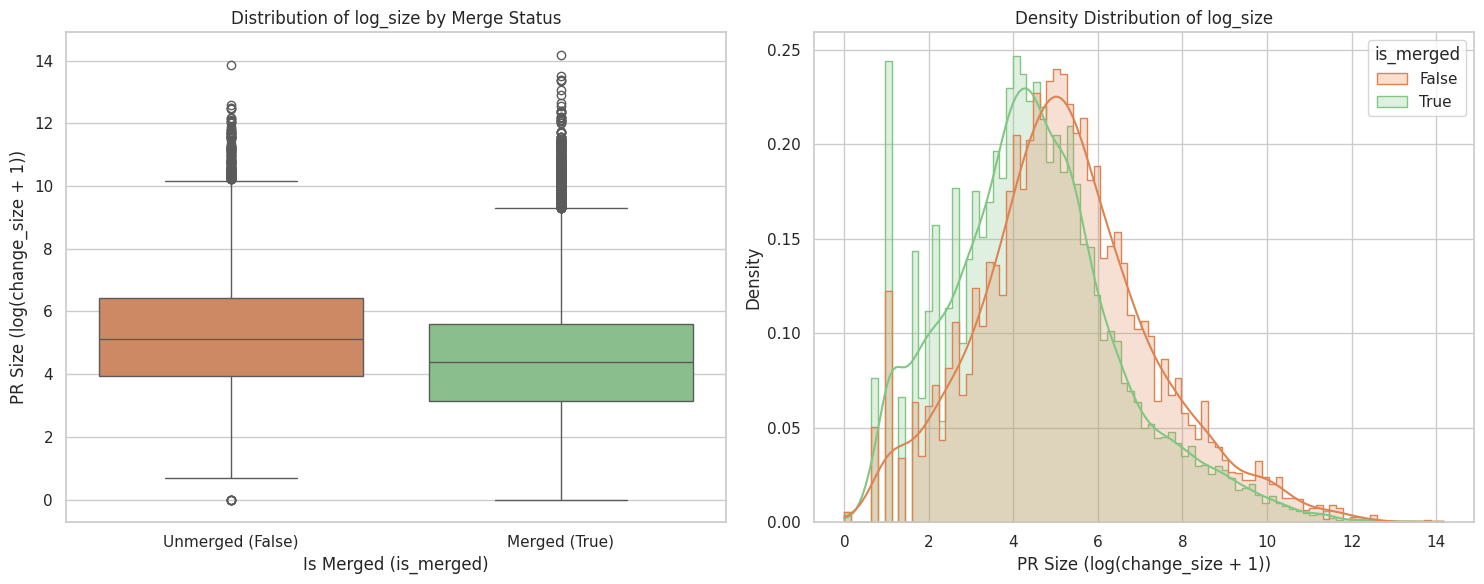

In [63]:
# Calculate descriptive statistics by merge status
stats_summary = rq2_df.groupby('is_merged')['change_size'].describe(percentiles=[0.25, 0.5, 0.75, 0.9])
display(stats_summary)
custom_palette = {False: '#DD8452', True: '#81C784'}

# Visualize size distribution (logarithmic scale)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=rq2_df, x='is_merged', y='log_size', hue='is_merged', ax=ax1, palette=custom_palette, legend=False)
ax1.set_title('Distribution of log_size by Merge Status')
ax1.set_xlabel('Is Merged (is_merged)')
ax1.set_ylabel('PR Size (log(change_size + 1))')
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['Unmerged (False)', 'Merged (True)'])

sns.histplot(data=rq2_df, x='log_size', hue='is_merged', kde=True, ax=ax2, element='step', stat='density', common_norm=False, palette=custom_palette)
ax2.set_title('Density Distribution of log_size')
ax2.set_xlabel('PR Size (log(change_size + 1))')
ax2.set_ylabel('Density')

plt.tight_layout()
plt.show()

As mentionned in part 2 change_size is highly right-skewed and contains extreme outliers, so we use a $\log(x+1)$ transformation for our analysis. The log transformation makes the distributions easier to compare, while adding 1 allows us to keep the 26 PRs with 0 lines changed.

The boxplot shows that unmerged PRs tend to be larger than merged PRs. The median size is 166 lines for unmerged PRs compared with 79 lines for merged PRs. Unmerged PRs show more variability in size, and both groups contain large outliers.

#### 3.2 Testing for Statistical Significance

Because PR size is highly skewed and contains extreme outliers, we use non-parametric tests:


*   A Mann-Whitney U test to test whether the size distributions of merged and unmerged PRs differ significantly
*   A Spearman rank correlation to measure the direction and strength of the relationship between PR size and merge status

In [64]:
# Separate the groups
merged_sizes = rq2_df[rq2_df['is_merged'] == True]['change_size']
unmerged_sizes = rq2_df[rq2_df['is_merged'] == False]['change_size']

# Mann-Whitney U Test
u_stat, p_val = stats.mannwhitneyu(merged_sizes, unmerged_sizes, alternative='two-sided')
print("Mann-Whitney U Test")
print(f"U-statistic: {u_stat}")
print(f"p-value: {p_val:.3e}")
if p_val < 0.05:
    print("Result: Significant (p < 0.05). The size of PRs differs significantly between merged and unmerged.\n")
else:
    print("Result: Not significant (p >= 0.05).\n")

# Spearman Correlation between change_size and is_merged
spearman_corr, spearman_p = stats.spearmanr(rq2_df['change_size'], rq2_df['is_merged'])
print("Spearman Correlation")
print(f"Correlation coefficient: {spearman_corr:.4f}")
print(f"p-value: {spearman_p:.3e}")

Mann-Whitney U Test
U-statistic: 64103970.0
p-value: 8.178e-164
Result: Significant (p < 0.05). The size of PRs differs significantly between merged and unmerged.

Spearman Correlation
Correlation coefficient: -0.1554
p-value: 8.595e-166


#### 3.3 Logistic Regression Model

To examine the relationship between PR size and merge outcome, we fit a logistic regression model. The target variable is is_merged (binary), and the predictor is log_size (continuous).

In [65]:
# Simple logistic regression model
# Convert boolean 'is_merged' to integer (0 or 1)
rq2_df['is_merged_int'] = rq2_df['is_merged'].astype(int)

model = smf.logit("is_merged_int ~ log_size", data=rq2_df).fit()
print(model.summary())

# Calculate the odds ratio
params = model.params
conf = model.conf_int()

or_table = pd.DataFrame({
    'Odds Ratio': np.exp(params),
    'CI Lower 95%': np.exp(conf.iloc[:, 0]),
    'CI Upper 95%': np.exp(conf.iloc[:, 1])
})

print("\n=== Odds Ratios and Confidence Intervals ===")
display(or_table)

Optimization terminated successfully.
         Current function value: 0.518270
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          is_merged_int   No. Observations:                30793
Model:                          Logit   Df Residuals:                    30791
Method:                           MLE   Df Model:                            1
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                 0.02009
Time:                        00:30:32   Log-Likelihood:                -15959.
converged:                       True   LL-Null:                       -16286.
Covariance Type:            nonrobust   LLR p-value:                2.443e-144
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.0713      0.036     57.602      0.000       2.001       2.142
log_size      -0.1677      0.

,Odds Ratio,CI Lower 95%,CI Upper 95%
Intercept,7.935406,7.395376,8.514870
log_size,0.845638,0.834805,0.856613


An Odds Ratio for log_size below 1 supports our hypothesis: larger AI-generated PRs are associated with lower odds of being merged. This relationship is statistically significant (p < 0.001).

#### RQ2 Summary (Size vs. Merge Rate)

Our results show that larger AI-generated PRs are generally less likely to be merged. This relationship is statistically significant across the Mann-Whitney U test, Spearman's correlation, and logistic regression.

However, the association is relatively weak (ρ = -0.155), and the low pseudo-R² (0.0201) suggests that PR size alone has limited explanatory power.

#CSV export

In [68]:

# Export cleaned datasets to CSV for GitHub
agent_pr.to_csv(
    os.path.join(CLEAN_DIR, 'agent_pr_clean.csv'),
    index=False
)

human_pr.to_csv(
    os.path.join(CLEAN_DIR, 'human_pr_clean.csv'),
    index=False
)

rq2.to_csv(
    os.path.join(CLEAN_DIR, 'agent_pr_size_clean.csv'),
    index=False
)

print("Cleaned CSV datasets exported successfully.")



Cleaned CSV datasets exported successfully.
